<a href="https://colab.research.google.com/github/dhana0020/Deep-Learning/blob/main/transfer_learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models


In [ ]:
import tensorflow_datasets as tfds

dataset, info = tfds.load("cats_vs_dogs", as_supervised=True, with_info=True)


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/cats_vs_dogs/incomplete.BURKO9_4.0.1/cats_vs_dogs-train.tfrecord*...:   0%…

Dataset cats_vs_dogs downloaded and prepared to /root/tensorflow_datasets/cats_vs_dogs/4.0.1. Subsequent calls will reuse this data.


In [ ]:
IMG_SIZE = 128
BATCH_SIZE = 32

def preprocess(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = image / 255.0
    return image, label

dataset = dataset['train'].map(preprocess)

dataset = dataset.shuffle(1000)


In [ ]:
total_size = info.splits['train'].num_examples
train_size = int(0.5 * total_size)

set_A = dataset.take(train_size)
set_B = dataset.skip(train_size)

set_A = set_A.batch(BATCH_SIZE)
set_B = set_B.batch(BATCH_SIZE)


In [ ]:
def build_model():
    model = models.Sequential([
        # 1
        layers.Conv2D(32, (3,3), activation='relu', input_shape=(128,128,3)),
        # 2
        layers.MaxPooling2D(2,2),

        # 3
        layers.Conv2D(64, (3,3), activation='relu'),
        # 4
        layers.MaxPooling2D(2,2),

        # 5
        layers.Conv2D(128, (3,3), activation='relu'),
        # 6
        layers.MaxPooling2D(2,2),

        # 7
        layers.Flatten(),
        layers.Dense(128, activation='relu'),

        # 8
        layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model


In [ ]:
model_scratch = build_model()

history_scratch = model_scratch.fit(
    set_A,
    epochs=10
)

model_scratch.save("pretrained_model.h5")


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 23s 44ms/step - accuracy: 0.5651 - loss: 0.7000
Epoch 2/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 16s 40ms/step - accuracy: 0.7122 - loss: 0.5627
Epoch 3/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 16s 41ms/step - accuracy: 0.7597 - loss: 0.4960
Epoch 4/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - accuracy: 0.8034 - loss: 0.4266
Epoch 5/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 15s 39ms/step - accuracy: 0.8427 - loss: 0.3574
Epoch 6/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - accuracy: 0.8735 - loss: 0.2921
Epoch 7/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 15s 37ms/step - accuracy: 0.9046 - loss: 0.2311
Epoch 8/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 16s 39ms/step - accuracy: 0.9308 - loss: 0.1812
Epoch 9/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 15s 40ms/step - accuracy: 0.9539 - loss: 0.1202
Epoch 10/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - accuracy: 0.9715 - loss: 0.0833


In [ ]:
model_tl_3 = tf.keras.models.load_model("pretrained_model.h5")

for layer in model_tl_3.layers[:3]:
    layer.trainable = False

model_tl_3.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_tl_3 = model_tl_3.fit(set_B, epochs=10)


Epoch 1/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 28s 37ms/step - accuracy: 0.8398 - loss: 0.3921
Epoch 2/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 32s 54ms/step - accuracy: 0.8846 - loss: 0.2743
Epoch 3/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 25s 35ms/step - accuracy: 0.9165 - loss: 0.2105
Epoch 4/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 41s 36ms/step - accuracy: 0.9442 - loss: 0.1464
Epoch 5/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 26s 37ms/step - accuracy: 0.9647 - loss: 0.1057
Epoch 6/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 27s 40ms/step - accuracy: 0.9773 - loss: 0.0663
Epoch 7/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 26s 37ms/step - accuracy: 0.9858 - loss: 0.0392
Epoch 8/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 26s 37ms/step - accuracy: 0.9879 - loss: 0.0348
Epoch 9/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 26s 37ms/step - accuracy: 0.9902 - loss: 0.0341
Epoch 10/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 26s 37ms/step - accuracy: 0.9920 - loss: 0.0288


In [ ]:
model_tl_6 = tf.keras.models.load_model("pretrained_model.h5")

for layer in model_tl_6.layers[:6]:
    layer.trainable = False

model_tl_6.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

history_tl_6 = model_tl_6.fit(set_B, epochs=10)


Epoch 1/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 29s 40ms/step - accuracy: 0.8320 - loss: 0.4151
Epoch 2/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 26s 36ms/step - accuracy: 0.8716 - loss: 0.3042
Epoch 3/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 26s 36ms/step - accuracy: 0.9039 - loss: 0.2381
Epoch 4/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 25s 34ms/step - accuracy: 0.9270 - loss: 0.1862
Epoch 5/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 25s 35ms/step - accuracy: 0.9495 - loss: 0.1369
Epoch 6/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 26s 37ms/step - accuracy: 0.9618 - loss: 0.0950
Epoch 7/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 27s 37ms/step - accuracy: 0.9770 - loss: 0.0694
Epoch 8/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 26s 37ms/step - accuracy: 0.9825 - loss: 0.0521
Epoch 9/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 26s 36ms/step - accuracy: 0.9888 - loss: 0.0344
Epoch 10/10
364/364 ━━━━━━━━━━━━━━━━━━━━ 26s 36ms/step - accuracy: 0.9907 - loss: 0.0282


comparison of performance

In [ ]:
print("Scratch Model Evaluation:")
model_scratch.evaluate(set_B)

print("Freeze 3 Evaluation:")
model_tl_3.evaluate(set_B)

print("Freeze 6 Evaluation:")
model_tl_6.evaluate(set_B)


Scratch Model Evaluation:
364/364 ━━━━━━━━━━━━━━━━━━━━ 27s 37ms/step - accuracy: 0.8316 - loss: 0.5017
Freeze 3 Evaluation:
364/364 ━━━━━━━━━━━━━━━━━━━━ 27s 37ms/step - accuracy: 0.9925 - loss: 0.0259
Freeze 6 Evaluation:
364/364 ━━━━━━━━━━━━━━━━━━━━ 39s 45ms/step - accuracy: 0.9881 - loss: 0.0353


[0.023938406258821487, 0.9920041561126709]

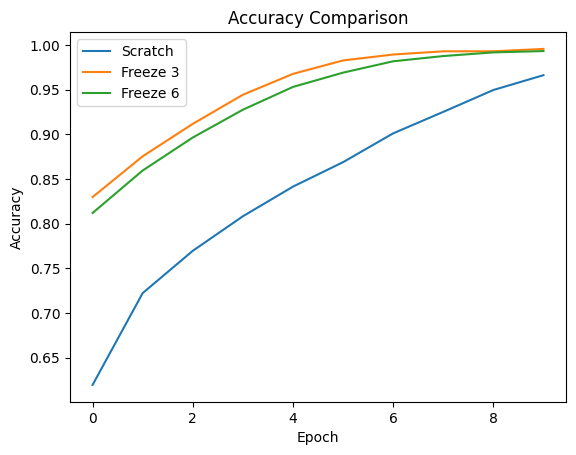

In [ ]:
plt.figure()

plt.plot(history_scratch.history['accuracy'], label='Scratch')
plt.plot(history_tl_3.history['accuracy'], label='Freeze 3')
plt.plot(history_tl_6.history['accuracy'], label='Freeze 6')

plt.title("Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()


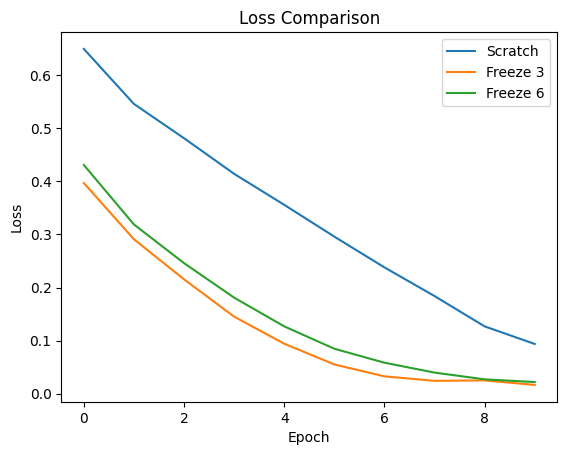

In [ ]:
plt.figure()

plt.plot(history_scratch.history['loss'], label='Scratch')
plt.plot(history_tl_3.history['loss'], label='Freeze 3')
plt.plot(history_tl_6.history['loss'], label='Freeze 6')

plt.title("Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()
